# Module 7 — Trees, Ensembles, Evaluation and Explainability
### मॉड्यूल 7 — Decision Trees, Ensembles, Evaluation और Explainability

> **Phase 2 · Classical ML** · scikit-learn; optional: xgboost, lightgbm, catboost, optuna, shap, imbalanced-learn (every optional import is guarded).
> Data: Titanic, Penguins, Breast Cancer (bundled), a synthetic imbalanced "transactions" set.

## 0. Module map

| # | Lesson | Outcome |
|---|---|---|
| 7.1 | Decision trees: Gini, entropy, recursion, stopping, pruning, regression trees | Build a tree split by hand and prune it with CV |
| 7.2 | Bagging, random forests, boosting, XGBoost/LightGBM/CatBoost | Know why ensembles win on tabular data and how to tune them |
| 7.3 | Validation (k-fold, stratified, grouped, nested) and hyperparameter search (grid, random, Optuna) | Get trustworthy scores and tune without fooling yourself |
| 7.4 | Imbalanced data (weights, resampling, SMOTE) and calibration + thresholds | Make "0.8" mean 80% and handle rare classes |
| 7.5 | Explainability: impurity vs permutation importance, SHAP, LIME — and their limits | Explain a model to a regulator without overclaiming |
| ★ | **Model Comparison Report** | A reproducible multi-model report with CV, calibration and SHAP |

```mermaid
flowchart TD
    T[Decision tree: greedy splits by Gini/entropy] -->|high variance| BAG[Bagging: average many trees]
    BAG --> RF[Random forest: + random features]
    T -->|high bias when shallow| BOOST[Boosting: trees fix previous errors]
    BOOST --> GBM[XGBoost / LightGBM / CatBoost / HistGB]
    RF & GBM --> VAL[Stratified / Group / Nested CV]
    VAL --> HP[Grid / Random / Optuna search]
    HP --> CAL[Calibration + threshold]
    CAL --> XAI[Permutation importance · SHAP · LIME]
```

In [1]:
from pathlib import Path
import importlib.util, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, cross_val_score, StratifiedKFold, KFold, GroupKFold,
                                     GridSearchCV, RandomizedSearchCV, cross_val_predict)
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss
np.set_printoptions(legacy="1.25")
has = lambda pkg: importlib.util.find_spec(pkg) is not None

def find_data() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        for c in (p / "datasets", p / "tutorials" / "data-science-ai" / "datasets"):
            if (c / "titanic.csv").exists():
                return c
    raise FileNotFoundError("Set DATA = Path('<path>/datasets')")

DATA = find_data(); rng = np.random.default_rng(7)
t = pd.read_csv(DATA / "titanic.csv")
X = pd.DataFrame({"female": (t.sex == "female").astype(int), "pclass": t.pclass, "age": t.age.fillna(-1),
                  "fare": t.fare, "sibsp": t.sibsp, "parch": t.parch,
                  "emb_C": (t.embarked == "C").astype(int), "emb_Q": (t.embarked == "Q").astype(int)})
y = t.survived
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
cv5 = StratifiedKFold(5, shuffle=True, random_state=0)
print({p: has(p) for p in ["xgboost", "lightgbm", "catboost", "optuna", "shap", "imblearn"]})

{'xgboost': True, 'lightgbm': True, 'catboost': False, 'optuna': True, 'shap': True, 'imblearn': True}


---

## Lesson 7.1 — Decision trees: splits, Gini, entropy, stopping, pruning
### पाठ 7.1 — Decision trees: splits, Gini, entropy, रुकना और pruning

**a. Concept (EN).** A tree asks yes/no questions ("fare ≤ 52?") recursively, choosing at each node the split that most reduces **impurity**: **Gini** = 1 − Σ pₖ² or **entropy** = −Σ pₖ log₂ pₖ (information gain = parent impurity − weighted child impurity). It's **greedy** (best split now, not globally). Without limits it grows until leaves are pure → memorises noise (high variance). **Stopping rules**: `max_depth`, `min_samples_leaf`, `min_impurity_decrease`. **Pruning**: grow big, then cut back with cost-complexity α (`ccp_alpha`) chosen by CV. **Regression trees** split to minimise MSE and predict the leaf mean (piecewise-constant). Trees need no scaling, handle interactions natively, but extrapolate poorly and are unstable (small data change → different tree).

**a. Concept (HI).** Tree हाँ/ना सवाल पूछता है और हर node पर वो split चुनता है जो impurity (Gini या entropy) सबसे ज़्यादा घटाए। यह greedy है — अभी का सबसे अच्छा। बिना सीमा के tree हर leaf को pure करके noise याद कर लेता है। रोकने के नियम: max_depth, min_samples_leaf; या पूरा बढ़ाकर `ccp_alpha` से काटो (pruning)। Regression tree leaf का mean बताता है। Scaling नहीं चाहिए, interactions खुद सीखता है, पर अस्थिर है और range के बाहर extrapolate नहीं करता।

**b. Analogy.** "20 Questions" / *Akinator*: each question should split the remaining possibilities as evenly and cleanly as possible. A fully grown tree is a student who writes a separate rule for every past exam question.

**c. Math, worked.** Root: 549 died, 342 survived → p = (0.616, 0.384); Gini = 1 − (0.616² + 0.384²) = **0.473**. Split on sex: female (233 surv / 314) Gini = 1 − (0.742² + 0.258²) = 0.383; male (109 / 577) Gini = 1 − (0.189² + 0.811²) = 0.306. Weighted = (314·0.383 + 577·0.306)/891 = 0.333 → **gain 0.140**.

In [2]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text

gini = lambda p: 1 - np.sum(np.square(p))
entropy = lambda p: -np.sum([q * np.log2(q) for q in p if q > 0])
def split_gain(df, col, thr=None, crit=gini):
    left = df[col] <= thr if thr is not None else df[col] == 1
    parts = [df.survived[left], df.survived[~left]]
    impurity = lambda s: crit([1 - s.mean(), s.mean()])
    return impurity(df.survived) - sum(len(s) / len(df) * impurity(s) for s in parts)

d = X.assign(survived=y)
print("root Gini:", round(gini([1 - y.mean(), y.mean()]), 3))
print("gain sex:", round(split_gain(d, "female"), 3), "| gain pclass≤2:", round(split_gain(d, "pclass", 2), 3),
      "| gain fare≤52:", round(split_gain(d, "fare", 52), 3), "| entropy gain sex:", round(split_gain(d, "female", crit=entropy), 3))

# Best threshold search for one numeric feature (what the tree does internally)
best = max(((split_gain(d, "fare", th), th) for th in np.unique(X.fare)[:-1]))
print(f"best fare threshold {best[1]:.2f} with gain {best[0]:.3f}")

# Overfitting vs depth; pruning with ccp_alpha chosen by CV
for depth in (2, 4, 8, None):
    m = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(Xtr, ytr)
    print(f"depth={str(depth):4s} leaves={m.get_n_leaves():3d} train={m.score(Xtr, ytr):.3f} test={m.score(Xte, yte):.3f}")
path = DecisionTreeClassifier(random_state=0).cost_complexity_pruning_path(Xtr, ytr)
alphas = path.ccp_alphas[::5]
cvs = [cross_val_score(DecisionTreeClassifier(ccp_alpha=a, random_state=0), Xtr, ytr, cv=cv5).mean() for a in alphas]
a_best = alphas[int(np.argmax(cvs))]
pruned = DecisionTreeClassifier(ccp_alpha=a_best, random_state=0).fit(Xtr, ytr)
print(f"pruned: alpha={a_best:.4f} leaves={pruned.get_n_leaves()} test={pruned.score(Xte, yte):.3f}")
print(export_text(DecisionTreeClassifier(max_depth=2, random_state=0).fit(X, y), feature_names=list(X.columns)))

# Regression tree: piecewise-constant predictions and no extrapolation
peng = pd.read_csv(DATA / "penguins.csv").dropna()
rt = DecisionTreeRegressor(max_depth=3).fit(peng[["flipper_length_mm"]], peng.body_mass_g)
print("regression tree predictions at 170/200/230/300 mm:", rt.predict(pd.DataFrame({"flipper_length_mm": [170, 200, 230, 300]})).round(0))

root Gini: 0.473
gain sex: 0.14 | gain pclass≤2: 0.049 | gain fare≤52: 0.04 | entropy gain sex: 0.218
best fare threshold 10.46 with gain 0.043
depth=2    leaves=  4 train=0.795 test=0.762
depth=4    leaves= 16 train=0.838 test=0.789
depth=8    leaves= 62 train=0.910 test=0.762
depth=None leaves=147 train=0.987 test=0.771


pruned: alpha=0.0020 leaves=38 test=0.807
|--- female <= 0.50
|   |--- fare <= 26.27
|   |   |--- class: 0
|   |--- fare >  26.27
|   |   |--- class: 0
|--- female >  0.50
|   |--- pclass <= 2.50
|   |   |--- class: 1
|   |--- pclass >  2.50
|   |   |--- class: 0

regression tree predictions at 170/200/230/300 mm: [3476. 3895. 5548. 5548.]


*Hindi summary:* Gini और information gain हाथ से निकाले — sex का split सबसे बड़ा gain (0.14) देता है। Depth बढ़ाने पर train accuracy 98% तक पर test गिरता है। CV से `ccp_alpha` चुनकर pruning की — कम leaves, बेहतर test। Regression tree 300 mm पर भी वही आख़िरी leaf का mean देता है — extrapolation नहीं।

**e. Traps.** Unlimited depth. Reading a single tree's structure as "the truth" (unstable). Using impurity-based importance on high-cardinality features (biased — Lesson 7.5). Interview: *"Gini vs entropy?"* Nearly identical splits in practice; Gini slightly faster (no log).

**f. Memory.** Mnemonic **"Grow Greedy, Prune Patiently."** **याद रखो:** *"पूरा बढ़ा tree = रट्टा मार छात्र।"*

| Q | A |
|---|---|
| Gini formula? | 1 − Σpₖ² |
| Information gain? | Parent impurity − weighted child impurity |
| Prune by? | `ccp_alpha` chosen by CV |
| Regression tree prediction? | Leaf mean |
| Do trees need scaling? | No |

**g. Practice.** (1) Gini of a node with 30 positives, 70 negatives. (2) Best `min_samples_leaf` ∈ {1, 5, 10, 20, 50} by CV. (3) Gain of splitting on `age ≤ 12` (treat -1 as unknown → right side).

**Solutions / हल**

In [3]:
print("1:", round(gini([0.3, 0.7]), 3))
print("2:", {m: round(cross_val_score(DecisionTreeClassifier(min_samples_leaf=m, random_state=0), Xtr, ytr, cv=cv5).mean(), 3) for m in (1, 5, 10, 20, 50)})
d2 = d.assign(child=((d.age >= 0) & (d.age <= 12)).astype(int)); print("3:", round(split_gain(d2, "child"), 4))

1: 0.42
2: {1: 0.778, 5: 0.802, 10: 0.804, 20: 0.795, 50: 0.787}
3: 0.0064


**h. Quiz.** 1) Max Gini for 2 classes? 2) Is tree building globally optimal? 3) What does `min_samples_leaf` reduce? 4) Tree prediction beyond training range? 5) Entropy of a pure node?

**Answers**1) 0.5. 2) No — greedy. 3) Variance/overfitting. 4) Constant (edge leaf). 5) 0.

---

## Lesson 7.2 — Bagging, random forests and boosting
### पाठ 7.2 — Bagging, random forests और boosting

**a. Concept (EN).** **Bagging** (bootstrap aggregating): train many deep trees on bootstrap samples and average → variance drops (≈ ρσ² + (1−ρ)σ²/B for correlation ρ). **Random forest** adds random feature subsets per split (`max_features`) → lower ρ → more variance reduction; free **out-of-bag (OOB)** validation (each tree skips ~36.8% of rows). **Boosting** fits shallow trees *sequentially*, each on the residuals/gradients of the current ensemble: Fₘ = Fₘ₋₁ + η·hₘ. **Learning rate** η trades speed for generalisation ("small rate, long runway"); use **early stopping** on a validation set. Industrial implementations: **XGBoost** (regularised objective, second-order gradients), **LightGBM** (histogram + leaf-wise growth, very fast), **CatBoost** (ordered boosting, native categoricals), and scikit-learn's **HistGradientBoosting** (LightGBM-style, native NaN and categorical support).

**a. Concept (HI).** Bagging: कई गहरे trees को अलग-अलग bootstrap samples पर train करके औसत लो — variance घटता है। Random forest हर split पर random features भी चुनता है, ताकि trees कम मिलते-जुलते हों; OOB rows से मुफ़्त validation। Boosting: छोटे trees एक के बाद एक, हर नया tree पिछली गलतियों (residuals) को ठीक करता है। Learning rate छोटा रखो और ज़्यादा trees, early stopping के साथ। XGBoost, LightGBM, CatBoost — industrial versions; scikit-learn का HistGradientBoosting भी तेज़ है।

**b. Analogy.** Bagging = asking 500 independent people to guess the weight of a cow and averaging (wisdom of crowds). Boosting = a relay of tutors where each one focuses only on the questions the previous tutors got wrong.

**c. Math.** Probability a row is *not* in a bootstrap sample of size n: (1 − 1/n)ⁿ → e⁻¹ ≈ **0.368**. Boosting for squared loss: residual rᵢ = yᵢ − Fₘ₋₁(xᵢ); fit hₘ to r; update F. Variance of an average of B trees with correlation ρ: ρσ² + (1−ρ)σ²/B → floor at ρσ² (why decorrelation matters).

In [4]:
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, GradientBoostingRegressor, HistGradientBoostingClassifier
print("P(row out-of-bag) for n=891:", round((1 - 1 / 891) ** 891, 4))

models = {"single tree": DecisionTreeClassifier(random_state=0),
          "bagging 300": BaggingClassifier(DecisionTreeClassifier(), n_estimators=300, random_state=0),
          "random forest": RandomForestClassifier(500, min_samples_leaf=2, oob_score=True, random_state=0),
          "hist GB": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=500, max_depth=3, early_stopping=True,
                                                    validation_fraction=0.15, random_state=0)}
for name, m in models.items():
    print(f"{name:14s} CV AUC {cross_val_score(m, Xtr, ytr, cv=cv5, scoring='roc_auc').mean():.3f}")
rf = models["random forest"].fit(Xtr, ytr); print("RF OOB accuracy:", round(rf.oob_score_, 3), "| test:", round(rf.score(Xte, yte), 3))

# Boosting from scratch (squared loss) on penguin mass — "trees hired to fix trees"
Xp, yp = peng[["flipper_length_mm", "bill_length_mm", "bill_depth_mm"]], peng.body_mass_g.to_numpy()
F = np.full(len(yp), yp.mean()); eta = 0.1
for m_ in range(1, 101):
    resid = yp - F
    h = DecisionTreeRegressor(max_depth=2).fit(Xp, resid)
    F += eta * h.predict(Xp)
    if m_ in (1, 10, 50, 100):
        print(f"round {m_:3d}: train RMSE {np.sqrt(np.mean((yp - F) ** 2)):.1f}")
print("sklearn GBR RMSE:", np.sqrt(np.mean((yp - GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=2).fit(Xp, yp).predict(Xp)) ** 2)).round(1))

# Learning rate vs runway, with early stopping
for lr in (0.3, 0.05):
    m = HistGradientBoostingClassifier(learning_rate=lr, max_iter=2000, early_stopping=True, n_iter_no_change=30, random_state=0).fit(Xtr, ytr)
    print(f"lr={lr}: stopped after {m.n_iter_} trees, test AUC {roc_auc_score(yte, m.predict_proba(Xte)[:, 1]):.3f}")

if has("xgboost") and has("lightgbm"):
    import xgboost as xgb, lightgbm as lgb
    for name, m in [("XGBoost", xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, eval_metric="auc")),
                    ("LightGBM", lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, subsample=0.8, subsample_freq=1, verbose=-1))]:
        print(f"{name:8s} CV AUC {cross_val_score(m, Xtr, ytr, cv=cv5, scoring='roc_auc').mean():.3f}")

P(row out-of-bag) for n=891: 0.3677
single tree    CV AUC 0.762


bagging 300    CV AUC 0.868


random forest  CV AUC 0.879


hist GB        CV AUC 0.863


RF OOB accuracy: 0.816 | test: 0.816
round   1: train RMSE 742.9
round  10: train RMSE 434.4
round  50: train RMSE 296.7
round 100: train RMSE 276.6
sklearn GBR RMSE: 276.6


lr=0.3: stopped after 37 trees, test AUC 0.827
lr=0.05: stopped after 84 trees, test AUC 0.836


XGBoost  CV AUC 0.866


LightGBM CV AUC 0.869


*Hindi summary:* 36.8% rows OOB रहती हैं। अकेले tree से bagging, फिर random forest, फिर boosting — AUC बढ़ता गया। Boosting को scratch से लिखा: हर round residuals पर एक छोटा tree, RMSE घटता गया, sklearn से match। छोटा learning rate = ज़्यादा trees पर अक्सर बेहतर; early stopping ने खुद रोका। XGBoost/LightGBM (अगर installed) भी उसी स्तर पर।

**e. Traps.** Tuning `n_estimators` for random forests (more is never worse, just slower) vs boosting (too many overfits → early stopping). Leaking the early-stopping validation set into test. Ignoring `scale_pos_weight` / class weights on imbalanced data. Interview: *"RF vs GBM?"* RF: robust, parallel, few knobs, lower ceiling. GBM: usually most accurate on tabular data, needs tuning + early stopping, sequential.

**f. Memory.** Mnemonic **"Bagging = Bheed ka average, Boosting = Badhti sudhaar."** **याद रखो:** *"Forest में पेड़ जितने चाहो, boosting में early stopping लगाओ।"*

| Q | A |
|---|---|
| Bagging reduces? | Variance |
| Boosting reduces mainly? | Bias (sequentially) |
| OOB fraction? | ≈ 36.8% |
| RF's extra randomness? | Random feature subset per split |
| Small learning rate needs? | More trees + early stopping |

**g. Practice.** (1) RF CV AUC for `max_features` ∈ {1, 3, "sqrt", None}. (2) Extend scratch boosting with η=0.5 and show it overfits faster on a held-out split. (3) Compare HistGB with native NaN handling (`age` as NaN instead of −1).

**Solutions / हल**

In [5]:
print("1:", {str(mf): round(cross_val_score(RandomForestClassifier(300, max_features=mf, random_state=0), Xtr, ytr, cv=cv5, scoring="roc_auc").mean(), 3) for mf in (1, 3, "sqrt", None)})
a, b, c, d_ = train_test_split(Xp, yp, test_size=0.3, random_state=0)
for eta_ in (0.1, 0.5):
    Fa, Fb = np.full(len(c), c.mean()), np.full(len(d_), c.mean())
    for _ in range(200):
        h = DecisionTreeRegressor(max_depth=3).fit(a, c - Fa); Fa += eta_ * h.predict(a); Fb += eta_ * h.predict(b)
    print(f"2: eta {eta_}: train RMSE {np.sqrt(np.mean((c-Fa)**2)):.0f}, test RMSE {np.sqrt(np.mean((d_-Fb)**2)):.0f}")
Xn = X.assign(age=t.age)
print("3: NaN-native HistGB AUC", round(cross_val_score(HistGradientBoostingClassifier(random_state=0), Xn, y, cv=cv5, scoring="roc_auc").mean(), 3))

1: {'1': 0.869, '3': 0.873, 'sqrt': 0.872, 'None': 0.868}


2: eta 0.1: train RMSE 134, test RMSE 364


2: eta 0.5: train RMSE 12, test RMSE 439


3: NaN-native HistGB AUC 0.861


**h. Quiz.** 1) Why do RF trees need to be decorrelated? 2) In boosting each tree fits? 3) Can RF overfit by adding trees? 4) LightGBM's growth strategy? 5) Which handles categoricals natively with ordered boosting?

**Answers**1) Averaging correlated errors doesn't cancel them (ρσ² floor). 2) Residuals / negative gradients. 3) No (variance converges), but individual deep trees can still overfit noise. 4) Leaf-wise (best-first). 5) CatBoost.

---

## Lesson 7.3 — Validation and hyperparameter search
### पाठ 7.3 — Validation और hyperparameter search

**a. Concept (EN).** **k-fold CV** averages k train/validate splits; **stratified** k-fold preserves class ratios (default for classification). **Grouped** CV (`GroupKFold`) keeps all rows of a group (patient, customer, store) in the same fold — otherwise you leak identity. **Time-series** CV only validates on the future. **Nested CV**: an inner loop tunes hyperparameters, an outer loop estimates performance of the *whole tuning procedure* — the only unbiased estimate when you tune heavily. Search: **grid** (exhaustive, wasteful in high-D), **random** (better coverage of important dimensions), **Bayesian/TPE** with **Optuna** (learns from past trials, prunes bad ones).

**a. Concept (HI).** k-fold CV कई splits का औसत देता है; stratified में class का अनुपात बना रहता है। Grouped CV में एक patient/customer की सारी rows एक ही fold में — वरना पहचान leak होती है। Time series में सिर्फ़ भविष्य पर validate। Nested CV: अंदर tuning, बाहर ईमानदार अनुमान। Search: grid (सब जगह), random (ज़रूरी dimensions को बेहतर cover), Optuna (पिछले trials से सीखता है)।

**b. Analogy.** Grid search = checking every shop on every street; random search = visiting random shops across the whole city (you find the good street faster); Optuna = a local friend who remembers which areas had good shops and sends you there.

**c. Math.** With 1 important and 9 unimportant hyperparameters, a 3¹⁰ grid tries only 3 distinct values of the important one; 60 random trials try ~60. Probability that ≥1 of n random trials lands in the top 5% of the space: 1 − 0.95ⁿ → n = 60 gives **95%** (Bergstra & Bengio).

In [6]:
from sklearn.datasets import load_breast_cancer
from scipy.stats import loguniform, randint
cancer = load_breast_cancer(as_frame=True); Xb, yb = cancer.data, 1 - cancer.target
print("P(≥1 of 60 random trials in top 5%):", round(1 - 0.95 ** 60, 3))

# Group leakage: duplicate "patients" (same row appears 3x with noise) inflate shuffled CV
patients = np.repeat(np.arange(len(Xb)), 3)
Xg = Xb.iloc[patients].reset_index(drop=True) * rng.normal(1, 0.01, (len(patients), Xb.shape[1]))
yg = yb.iloc[patients].reset_index(drop=True)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(1))
print("1-NN shuffled KFold acc:", cross_val_score(knn, Xg, yg, cv=KFold(5, shuffle=True, random_state=0)).mean().round(3),
      "| GroupKFold acc:", cross_val_score(knn, Xg, yg, cv=GroupKFold(5), groups=patients).mean().round(3))

# Grid vs random search on random forest
rf = RandomForestClassifier(random_state=0, n_jobs=-1)
grid = GridSearchCV(rf, {"n_estimators": [200], "max_depth": [3, 6, None], "min_samples_leaf": [1, 5, 20]}, cv=cv5, scoring="roc_auc").fit(Xtr, ytr)
rand = RandomizedSearchCV(rf, {"n_estimators": [200], "max_depth": randint(2, 20), "min_samples_leaf": randint(1, 40),
                               "max_features": loguniform(0.1, 1.0)}, n_iter=15, cv=cv5, scoring="roc_auc", random_state=0).fit(Xtr, ytr)
print(f"grid best {grid.best_score_:.3f} {grid.best_params_}\nrandom best {rand.best_score_:.3f} { {k: (round(v, 3) if isinstance(v, float) else v) for k, v in rand.best_params_.items()} }")

# Nested CV: honest estimate of "tune + fit"
inner = GridSearchCV(HistGradientBoostingClassifier(random_state=0), {"learning_rate": [0.03, 0.1], "max_depth": [2, 4]}, cv=3, scoring="roc_auc")
nested = cross_val_score(inner, Xtr, ytr, cv=cv5, scoring="roc_auc")
print(f"nested CV AUC {nested.mean():.3f} ± {nested.std():.3f}")

if has("optuna"):
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    def objective(trial):
        m = HistGradientBoostingClassifier(learning_rate=trial.suggest_float("lr", 0.01, 0.3, log=True),
                                           max_depth=trial.suggest_int("max_depth", 2, 8),
                                           min_samples_leaf=trial.suggest_int("min_leaf", 5, 80), random_state=0)
        return cross_val_score(m, Xtr, ytr, cv=cv5, scoring="roc_auc").mean()
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
    study.optimize(objective, n_trials=20)
    print(f"optuna best {study.best_value:.3f} {study.best_params}")

P(≥1 of 60 random trials in top 5%): 0.954
1-NN shuffled KFold acc: 0.998 | GroupKFold acc: 0.957


grid best 0.874 {'max_depth': 6, 'min_samples_leaf': 1, 'n_estimators': 200}
random best 0.879 {'max_depth': 16, 'max_features': 0.526, 'min_samples_leaf': 2, 'n_estimators': 200}


nested CV AUC 0.862 ± 0.022


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


optuna best 0.868 {'lr': 0.15151446654565384, 'max_depth': 5, 'min_leaf': 64}


*Hindi summary:* हर patient की 3 copies वाले data पर shuffled CV में 1-NN लगभग 100% (leak!), GroupKFold पर असली score। Grid और random search की तुलना; nested CV से tuning की ईमानदार accuracy; Optuna ने 20 trials में अच्छे parameters ढूँढे।

**e. Traps.** Reporting `best_score_` of a big search as the expected performance (optimistic — use nested CV or a fresh test set). Non-stratified folds on rare classes. Shuffling time series. Interview: *"Why is nested CV needed?"* The inner search's best score is selected from many noisy estimates → biased upward; the outer loop measures the whole procedure.

**f. Memory.** Mnemonic **"Stratify classes, Group identities, Time forward, Nest when tuning."** **याद रखो:** *"Best score दिखाकर ख़ुश मत हो — nested CV से पूछो।"*

| Q | A |
|---|---|
| CV preserving class ratio? | StratifiedKFold |
| Same patient in many rows? | GroupKFold |
| Unbiased estimate when tuning? | Nested CV |
| Why random > grid? | Explores important dims better |
| Optuna's default sampler? | TPE (Bayesian-style) |

**g. Practice.** (1) 10-fold vs 3-fold CV AUC and std for RF. (2) RandomizedSearch on logistic C ∈ loguniform(1e-3, 1e2) for breast cancer. (3) Why might GroupKFold scores be lower — and which one would you report?

**Solutions / हल**

In [7]:
for k in (3, 10):
    s = cross_val_score(RandomForestClassifier(200, random_state=0), Xtr, ytr, cv=StratifiedKFold(k, shuffle=True, random_state=0), scoring="roc_auc")
    print(f"1: {k}-fold {s.mean():.3f} ± {s.std():.3f}")
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
rs = RandomizedSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)), {"logisticregression__C": loguniform(1e-3, 1e2)},
                        n_iter=20, cv=cv5, scoring="roc_auc", random_state=0).fit(Xb, yb)
print("2:", round(rs.best_score_, 4), round(rs.best_params_["logisticregression__C"], 4))
print("3: GroupKFold removes identity leakage; report it — it matches deployment on new patients.")

1: 3-fold 0.862 ± 0.014


1: 10-fold 0.873 ± 0.035


2: 0.9956 0.441
3: GroupKFold removes identity leakage; report it — it matches deployment on new patients.


**h. Quiz.** 1) k-fold with k=n is called? 2) Can you use the test set to pick hyperparameters? 3) TimeSeriesSplit validates on? 4) Which search scales best to 10 hyperparameters? 5) Does more folds always mean a better estimate?

**Answers**1) Leave-one-out. 2) No. 3) Later time periods. 4) Random / Bayesian (Optuna). 5) No — less bias but more variance and cost; 5–10 is typical.

---

## Lesson 7.4 — Imbalanced data, SMOTE, calibration and thresholds
### पाठ 7.4 — Imbalanced data, SMOTE, calibration और thresholds

**a. Concept (EN).** With rare positives (fraud 0.5%), models learn to ignore them. Options: **class weights** (`class_weight="balanced"`, `scale_pos_weight`) — cheapest, no data change; **undersampling** the majority ("the skip"); **oversampling**/**SMOTE** — synthesise minority points by interpolating between minority neighbours ("changing the room, with rules": only inside training folds, never on validation/test). Often the best fix is just a good ranking model + a **threshold** chosen for cost. **Calibration**: a model is calibrated if among predictions of 0.8, ~80% are positive. Trees/boosting/SVMs/NB are often miscalibrated; resampling and class weights *break* calibration. Fix with **Platt scaling** (sigmoid) or **isotonic regression** (`CalibratedClassifierCV`), measure with **reliability diagrams**, **Brier score** (mean squared error of probabilities) and log-loss.

**a. Concept (HI).** जब positives बहुत कम हों तो model उन्हें नज़रअंदाज़ करना सीख लेता है। उपाय: class weights (सबसे आसान), majority को कम करना (undersampling), या SMOTE — minority points के बीच नए synthetic points बनाना — पर सिर्फ़ training fold के अंदर! अक्सर सबसे अच्छा: अच्छा ranking model + cost से threshold। Calibration: 0.8 बोले तो 80% बार सच हो। Resampling और weights calibration बिगाड़ते हैं; Platt (sigmoid) या isotonic से ठीक करो, Brier score और reliability diagram से जाँचो।

**b. Analogy.** A weather app that says "80% rain" should be right about 8 out of 10 such days — that's calibration. SMOTE = making extra practice questions *between* two real hard questions, but only in your practice book, never in the exam.

**c. Math.** Brier = (1/n)Σ(pᵢ − yᵢ)². Weighted loss with w₊ = n/(2n₊): for 1% positives, w₊ = 50 — each positive counts 50×. Prior shift correction after resampling to 50/50: p_true = p·π / (p·π + (1−p)(1−π)·(π_s/(1−π_s))), with π the true and π_s the sampled positive rate.

positive rate: 0.02
plain              ROC-AUC 0.956 PR-AUC 0.605 Brier 0.0117 mean p 0.021 (true rate 0.020)
class_weight       ROC-AUC 0.960 PR-AUC 0.554 Brier 0.0805 mean p 0.175 (true rate 0.020)
SMOTE (train only) ROC-AUC 0.958 PR-AUC 0.594 Brier 0.0183 mean p 0.051 (true rate 0.020)


HistGB raw           Brier 0.0082 log-loss 0.0331
HistGB isotonic      Brier 0.0072 log-loss 0.0286
weighted LR + Platt  Brier 0.0127 log-loss 0.0489


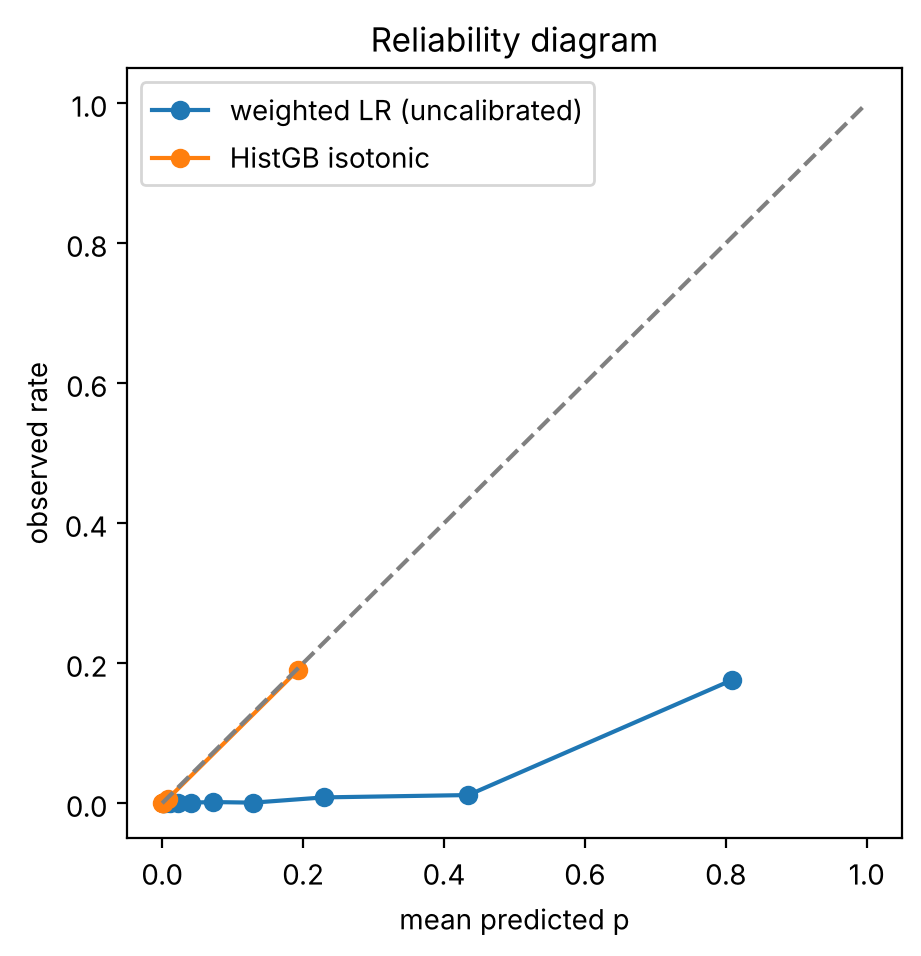

In [8]:
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.neighbors import NearestNeighbors

Xi, yi = make_classification(30_000, 15, n_informative=6, weights=[0.98], class_sep=0.9, flip_y=0, random_state=1)
a, b, c, d = train_test_split(Xi, yi, test_size=0.4, stratify=yi, random_state=0)
print("positive rate:", c.mean().round(4))

def smote(Xm, k=5, n_new=None, seed=0):
    """Minimal SMOTE: interpolate each synthetic point between a minority point and one of its k minority neighbours."""
    r = np.random.default_rng(seed); n_new = n_new or len(Xm)
    nn = NearestNeighbors(n_neighbors=k + 1).fit(Xm); idx = nn.kneighbors(Xm, return_distance=False)[:, 1:]
    i = r.integers(0, len(Xm), n_new); j = idx[i, r.integers(0, k, n_new)]
    return Xm[i] + r.random((n_new, 1)) * (Xm[j] - Xm[i])

Xmin = a[c == 1]; Xsyn = smote(Xmin, n_new=4 * len(Xmin))
a_sm, c_sm = np.vstack([a, Xsyn]), np.r_[c, np.ones(len(Xsyn), int)]
variants = {"plain": LogisticRegression(max_iter=2000).fit(a, c),
            "class_weight": LogisticRegression(max_iter=2000, class_weight="balanced").fit(a, c),
            "SMOTE (train only)": LogisticRegression(max_iter=2000).fit(a_sm, c_sm)}
for name, m in variants.items():
    p = m.predict_proba(b)[:, 1]
    print(f"{name:18s} ROC-AUC {roc_auc_score(d, p):.3f} PR-AUC {average_precision_score(d, p):.3f} "
          f"Brier {brier_score_loss(d, p):.4f} mean p {p.mean():.3f} (true rate {d.mean():.3f})")

# Calibration of a boosted model: raw vs isotonic
gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=0)
raw = gb.fit(a, c).predict_proba(b)[:, 1]
iso = CalibratedClassifierCV(HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=0), method="isotonic", cv=3).fit(a, c).predict_proba(b)[:, 1]
wt = CalibratedClassifierCV(LogisticRegression(max_iter=2000, class_weight="balanced"), method="sigmoid", cv=3).fit(a, c).predict_proba(b)[:, 1]
for name, p in [("HistGB raw", raw), ("HistGB isotonic", iso), ("weighted LR + Platt", wt)]:
    print(f"{name:20s} Brier {brier_score_loss(d, p):.4f} log-loss {log_loss(d, p):.4f}")

fig, ax = plt.subplots(figsize=(5, 5))
for name, p in [("weighted LR (uncalibrated)", variants["class_weight"].predict_proba(b)[:, 1]), ("HistGB isotonic", iso)]:
    fp, mp = calibration_curve(d, p, n_bins=10, strategy="quantile"); ax.plot(mp, fp, "o-", label=name)
ax.plot([0, 1], [0, 1], "--", c="gray"); ax.set(xlabel="mean predicted p", ylabel="observed rate", title="Reliability diagram"); ax.legend(); plt.show()

*Hindi summary:* अपना छोटा SMOTE लिखा (सिर्फ़ training data पर)। Class weights और SMOTE से ranking (AUC) लगभग वैसी ही रही पर average probability असली rate से बहुत ऊपर — calibration टूट गया (Brier बढ़ा)। Isotonic/Platt calibration से Brier सुधरा; reliability diagram पर weighted model diagonal से दूर, calibrated पास।

**e. Traps.** SMOTE before the split / inside CV without a pipeline (`imblearn.pipeline.Pipeline` fixes it). Judging resampling by accuracy. Using probabilities from a resampled/weighted model as real risk without recalibration. Calibrating on the training data. Interview: *"Do you need SMOTE?"* Often not: modern GBMs + class weights + threshold tuning match it; SMOTE can add noise in high-D or with overlapping classes.

**f. Memory.** Mnemonic **"Weight, Sample, Threshold, Calibrate" (W-S-T-C).** **याद रखो:** *"0.8 का मतलब 80% — वरना calibrate करो।"*

| Q | A |
|---|---|
| Cheapest imbalance fix? | Class weights |
| Where to apply SMOTE? | Training folds only |
| Calibration metric? | Brier score / reliability diagram |
| Platt vs isotonic? | Sigmoid (few data) vs non-parametric (more data) |
| Does class weighting change AUC much? | Usually little; it shifts probabilities |

**g. Practice.** (1) Undersample the majority to 10:1 and compare PR-AUC. (2) Apply the prior-shift correction to the SMOTE model's probabilities and recompute Brier. (3) If `imblearn` is installed, run its SMOTE inside an imblearn Pipeline with CV.

**Solutions / हल**

In [9]:
neg = np.where(c == 0)[0]; pos = np.where(c == 1)[0]
keep = np.r_[pos, rng.choice(neg, 10 * len(pos), replace=False)]
pu = LogisticRegression(max_iter=2000).fit(a[keep], c[keep]).predict_proba(b)[:, 1]
print("1: undersampled PR-AUC", round(average_precision_score(d, pu), 3))
ps = variants["SMOTE (train only)"].predict_proba(b)[:, 1]; pi, pis = c.mean(), c_sm.mean()
odds = ps / (1 - ps) * (pi / (1 - pi)) / (pis / (1 - pis)); pc = odds / (1 + odds)
print("2: Brier before", round(brier_score_loss(d, ps), 4), "after correction", round(brier_score_loss(d, pc), 4))
if has("imblearn"):
    from imblearn.pipeline import make_pipeline as imb_pipe
    from imblearn.over_sampling import SMOTE
    print("3: imblearn SMOTE CV PR-AUC", round(cross_val_score(imb_pipe(SMOTE(random_state=0), LogisticRegression(max_iter=2000)),
                                                               a, c, cv=StratifiedKFold(3, shuffle=True, random_state=0), scoring="average_precision").mean(), 3))

1: undersampled PR-AUC 0.587
2: Brier before 0.0183 after correction 0.0121


3: imblearn SMOTE CV PR-AUC 0.539


**h. Quiz.** 1) What does a calibrated 0.3 mean? 2) Brier of always predicting the base rate π? 3) Why does class weighting break calibration? 4) Should validation folds be SMOTE'd? 5) Reliability curve above the diagonal means?

**Answers**1) ~30% of such cases are positive. 2) π(1−π). 3) It changes the effective prior the model learns. 4) Never. 5) Under-confident (observed rate > predicted).

---

## Lesson 7.5 — Explainability: importance, SHAP, LIME and their limits
### पाठ 7.5 — Explainability: importance, SHAP, LIME और उनकी सीमाएँ

**a. Concept (EN).** **Impurity (MDI) importance** from trees is fast but biased toward high-cardinality/continuous features and computed on training data. **Permutation importance**: shuffle one feature on validation data and measure the score drop — model-agnostic and honest, but correlated features share/hide importance. **Partial dependence / ICE**: average/individual prediction as one feature varies. **SHAP** (Shapley values from game theory): each feature's fair contribution to moving a prediction from the baseline (average prediction) — local *and* global, additive: f(x) = φ₀ + Σφⱼ. TreeSHAP computes it exactly for trees. **LIME**: fit a simple local surrogate around one prediction — intuitive but unstable. **Limits**: explanations describe the *model*, not causality ("what explanations can't prove"); correlated features make attributions ambiguous; explanations can be gamed.

**a. Concept (HI).** Tree की impurity importance तेज़ है पर continuous / बहुत unique values वाले features की ओर झुकी हुई। Permutation importance: validation पर एक feature shuffle करो और देखो score कितना गिरा — ईमानदार, पर correlated features में बँट जाती है। SHAP: game theory से हर feature का "उचित हिस्सा" कि prediction average से कितना हटा — हर row के लिए भी और global भी, और सब जोड़ने पर prediction बनता है। LIME: एक prediction के आस-पास छोटा simple model। सीमा: explanation model के बारे में है, cause के बारे में नहीं।

**b. Analogy.** Shapley values = fairly splitting a restaurant bill among friends who ordered shared dishes, by averaging each person's marginal contribution over every order in which they could have arrived. Permutation importance = removing one player from the team (by scrambling their moves) and seeing how much the team's score drops.

**c. Math.** Shapley: φⱼ = Σ_{S ⊆ F∖{j}} |S|!(|F|−|S|−1)!/|F|! · [v(S ∪ {j}) − v(S)]. For a linear model with independent features, φⱼ = βⱼ(xⱼ − E[xⱼ]) — a check we run below.

        MDI (train)  permutation (test)
female        0.262               0.161
pclass        0.090               0.059
fare          0.196               0.041
age           0.153               0.027
parch         0.038               0.018
sibsp         0.042               0.011
emb_Q         0.011               0.009
noise         0.188               0.005
emb_C         0.019               0.003


passenger: {'female': 0.0, 'pclass': 2.0, 'age': 42.0, 'fare': 13.0, 'sibsp': 0.0, 'parch': 0.0, 'emb_C': 0.0, 'emb_Q': 0.0}
φ: {'female': -0.221, 'age': -0.092, 'pclass': 0.034, 'parch': -0.019, 'sibsp': 0.015, 'emb_C': -0.007, 'emb_Q': 0.004, 'fare': 0.0}
additivity: base 0.381 + Σφ -0.287 = 0.094 vs prediction 0.094


SHAP global mean|φ|: {'female': 0.201, 'pclass': 0.093, 'fare': 0.055, 'age': 0.035}


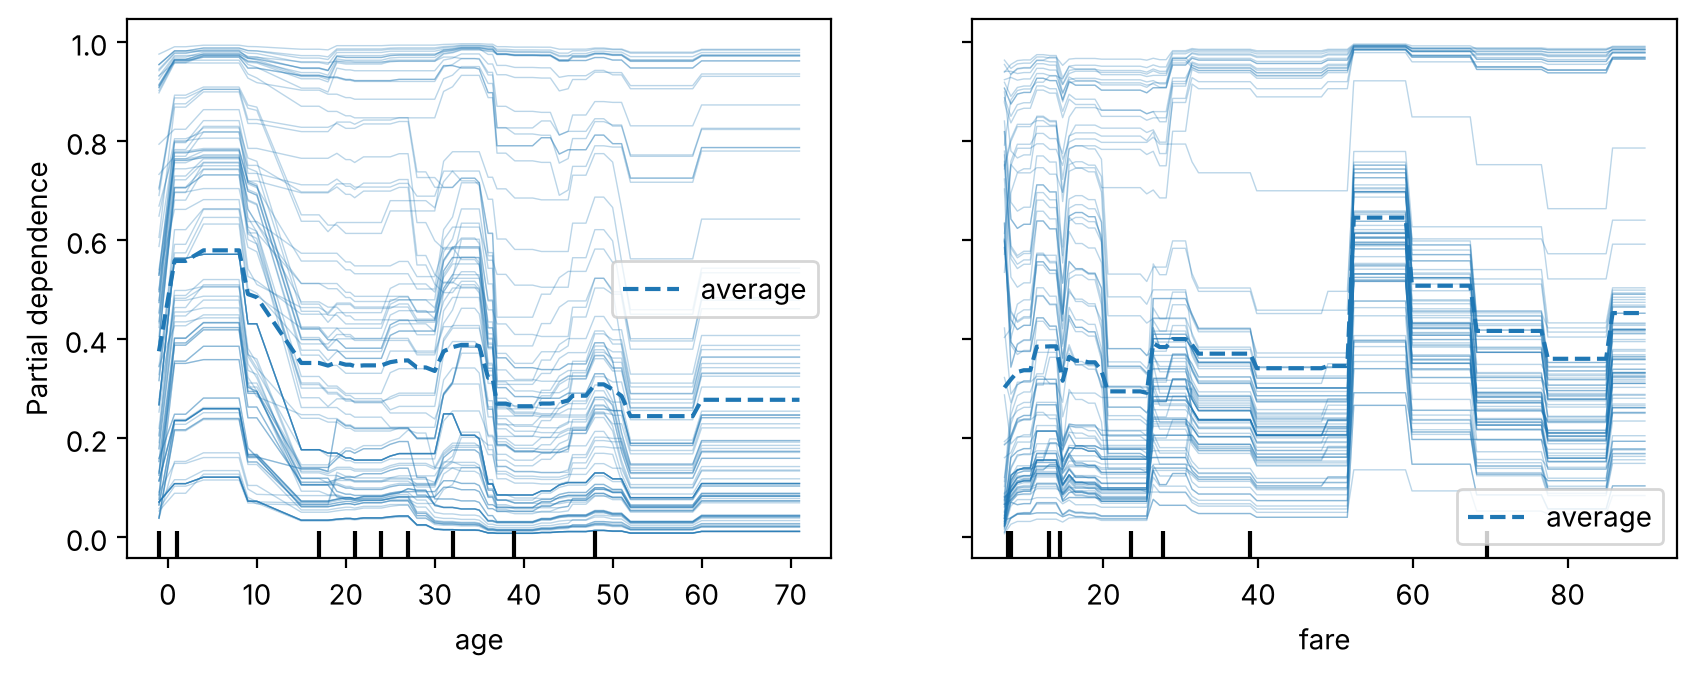

In [10]:
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from itertools import combinations
from math import factorial

# Bias of impurity importance: add a pure-noise continuous column
Xn = Xtr.assign(noise=rng.normal(size=len(Xtr))); Xnt = Xte.assign(noise=rng.normal(size=len(Xte)))
rf = RandomForestClassifier(400, random_state=0).fit(Xn, ytr)
imp = pd.DataFrame({"MDI (train)": rf.feature_importances_,
                    "permutation (test)": permutation_importance(rf, Xnt, yte, n_repeats=20, random_state=0, scoring="roc_auc").importances_mean},
                   index=Xn.columns).round(3).sort_values("permutation (test)", ascending=False)
print(imp)

# Exact Shapley values by brute force for one passenger (8 features → 256 coalitions), "absent" = background mean
hgb = HistGradientBoostingClassifier(max_depth=3, random_state=0).fit(Xtr, ytr)
bg = Xtr.sample(200, random_state=0); x0 = Xte.iloc[[0]]
def v(S):                                            # value of coalition S: mean prediction with S fixed to x0
    Z = bg.copy()
    for col in S:
        Z[col] = x0[col].values[0]
    return hgb.predict_proba(Z)[:, 1].mean()
F = list(X.columns); n = len(F); phi = {}
for j in F:
    rest = [f for f in F if f != j]
    phi[j] = sum(factorial(len(S)) * factorial(n - len(S) - 1) / factorial(n) * (v(S + (j,)) - v(S))
                 for k in range(n) for S in combinations(rest, k))
base, full = v(()), v(tuple(F))
print("passenger:", x0.iloc[0].to_dict())
print("φ:", {k: round(val, 3) for k, val in sorted(phi.items(), key=lambda kv: -abs(kv[1]))})
print(f"additivity: base {base:.3f} + Σφ {sum(phi.values()):.3f} = {base + sum(phi.values()):.3f} vs prediction {full:.3f}")

if has("shap"):
    import shap
    expl = shap.TreeExplainer(rf); sv = expl.shap_values(Xnt.iloc[:200])
    sv1 = sv[..., 1] if np.ndim(sv) == 3 else sv[1]
    print("SHAP global mean|φ|:", pd.Series(np.abs(sv1).mean(0), index=Xn.columns).round(3).sort_values(ascending=False).head(4).to_dict())

fig, ax = plt.subplots(figsize=(10, 3.5))
PartialDependenceDisplay.from_estimator(hgb, Xte, ["age", "fare"], kind="both", subsample=100, random_state=0, ax=ax); plt.show()

*Hindi summary:* Pure noise column को MDI importance ने कुछ महत्व दिया (bias), permutation importance ने ≈ 0 — ईमानदार। एक passenger के लिए Shapley values 256 coalitions से brute force निकालीं; base + Σφ = prediction (additivity)। SHAP library (अगर है) से global importance, और PDP/ICE plots से age और fare का असर।

**e. Traps.** Explaining a bad model. Treating SHAP as causal ("raising fare would raise survival"). Permutation importance on training data. Ignoring correlated features (shuffling creates impossible rows). LIME's instability across runs. Interview: *"MDI vs permutation vs SHAP?"* Fast-but-biased vs honest-global-but-correlation-sensitive vs local+global additive attributions with stronger theory but costlier and still not causal.

**f. Memory.** Mnemonic **"SHAP Shares fairly, Permutation Punishes, MDI Misleads."** **याद रखो:** *"Explanation model की कहानी है, दुनिया की नहीं।"*

| Q | A |
|---|---|
| Why is MDI biased? | Favours continuous/high-cardinality features; train-set based |
| Permutation importance computed on? | Validation/test data |
| SHAP additivity? | base + Σφ = prediction |
| LIME? | Local linear surrogate |
| Does SHAP prove causality? | No |

**g. Practice.** (1) Duplicate `fare` as `fare_copy` and show how permutation importance splits between them. (2) Verify φⱼ = βⱼ(xⱼ − mean) for a linear regression on penguins. (3) Write a 3-sentence explanation of passenger 0's prediction for a non-technical reader.

**Solutions / हल**

In [11]:
Xc, Xct = Xtr.assign(fare_copy=Xtr.fare), Xte.assign(fare_copy=Xte.fare)
rfc = RandomForestClassifier(300, random_state=0).fit(Xc, ytr)
pi = permutation_importance(rfc, Xct, yte, n_repeats=20, random_state=0, scoring="roc_auc").importances_mean
print("1:", dict(zip(Xc.columns, pi.round(3))))
from sklearn.linear_model import LinearRegression
Xl = peng[["flipper_length_mm", "bill_length_mm"]]; lr_ = LinearRegression().fit(Xl, peng.body_mass_g)
x = Xl.iloc[0]; print("2: linear SHAP φ =", (lr_.coef_ * (x - Xl.mean())).round(1).to_dict())
top = sorted(phi.items(), key=lambda kv: -abs(kv[1]))[:2]
print(f"3: The model's average survival estimate is {base:.0%}. For this passenger it is {full:.0%}. "
      f"The biggest factors were {top[0][0]} ({top[0][1]:+.0%}) and {top[1][0]} ({top[1][1]:+.0%}); this describes the model, not cause and effect.")

1: {'female': 0.155, 'pclass': 0.06, 'age': 0.025, 'fare': 0.004, 'sibsp': 0.005, 'parch': 0.015, 'emb_C': -0.002, 'emb_Q': 0.01, 'fare_copy': 0.005}
2: linear SHAP φ = {'flipper_length_mm': -976.2, 'bill_length_mm': -24.3}
3: The model's average survival estimate is 38%. For this passenger it is 9%. The biggest factors were female (-22%) and age (-9%); this describes the model, not cause and effect.


**h. Quiz.** 1) Permutation importance of a feature with a duplicate copy? 2) SHAP baseline φ₀ is? 3) PDP shows? 4) Why can explanations be "gamed"? 5) Exact Shapley cost for n features?

**Answers**1) Each copy looks less important (redundancy). 2) Expected model output over the background data. 3) Average prediction as one feature varies. 4) Models can behave differently off-distribution, where perturbation-based explainers probe. 5) O(2ⁿ) coalitions (TreeSHAP is polynomial for trees).

---

## ★ Project — Model Comparison Report
### ★ Project — Model Comparison Report (कई models की ईमानदार तुलना)

**Goal:** compare 4 model families on the breast-cancer risk task with the same folds, report mean ± sd for ROC-AUC, PR-AUC, Brier and fit time, test significance of the top-2 difference with a paired comparison across folds, calibrate the winner, and produce a markdown report table.

In [12]:
import time
from sklearn.preprocessing import StandardScaler
from scipy import stats
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.25, stratify=yb, random_state=42)
families = {"LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=0.5)),
            "RandomForest": RandomForestClassifier(400, min_samples_leaf=2, random_state=0, n_jobs=-1),
            "HistGB": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_depth=3, random_state=0),
            "DecisionTree": DecisionTreeClassifier(max_depth=4, random_state=0)}
if has("xgboost"):
    import xgboost as xgb; families["XGBoost"] = xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8)
folds = list(StratifiedKFold(5, shuffle=True, random_state=0).split(Xb_tr, yb_tr)); rows, per_fold = [], {}
for name, model in families.items():
    aucs, aps, briers, secs = [], [], [], []
    for tr, va in folds:
        t0 = time.perf_counter(); model.fit(Xb_tr.iloc[tr], yb_tr.iloc[tr]); secs.append(time.perf_counter() - t0)
        p = model.predict_proba(Xb_tr.iloc[va])[:, 1]; yv = yb_tr.iloc[va]
        aucs.append(roc_auc_score(yv, p)); aps.append(average_precision_score(yv, p)); briers.append(brier_score_loss(yv, p))
    per_fold[name] = np.array(aucs)
    rows.append({"model": name, "ROC-AUC": f"{np.mean(aucs):.4f} ± {np.std(aucs):.4f}", "PR-AUC": f"{np.mean(aps):.4f}",
                 "Brier": f"{np.mean(briers):.4f}", "fit s": f"{np.mean(secs):.2f}", "_auc": np.mean(aucs)})
table = pd.DataFrame(rows).sort_values("_auc", ascending=False)
print(table.drop(columns="_auc").to_markdown(index=False) if has("tabulate") else table.drop(columns="_auc").to_string(index=False))

first, second = table.model.iloc[0], table.model.iloc[1]
tstat, pval = stats.ttest_rel(per_fold[first], per_fold[second])
print(f"\n{first} vs {second}: mean ΔAUC {np.mean(per_fold[first]-per_fold[second]):+.4f}, paired t p={pval:.3f} "
      f"({'difference not reliable with 5 folds' if pval > 0.05 else 'significant'})")

winner = CalibratedClassifierCV(families[first], method="sigmoid", cv=5).fit(Xb_tr, yb_tr)
pt = winner.predict_proba(Xb_te)[:, 1]
print(f"TEST (once) — calibrated {first}: ROC-AUC {roc_auc_score(yb_te, pt):.4f}, PR-AUC {average_precision_score(yb_te, pt):.4f}, Brier {brier_score_loss(yb_te, pt):.4f}")
print("\nRecommendation: ship the simplest model within noise of the best (check the paired test above), calibrated, with its threshold set by cost (Module 6).")

       model         ROC-AUC PR-AUC  Brier fit s
      LogReg 0.9926 ± 0.0114 0.9916 0.0234  0.00
     XGBoost 0.9900 ± 0.0107 0.9885 0.0263  0.13
      HistGB 0.9864 ± 0.0137 0.9867 0.0284  0.21
RandomForest 0.9857 ± 0.0112 0.9845 0.0356  0.66
DecisionTree 0.9195 ± 0.0223 0.8727 0.0673  0.00

LogReg vs XGBoost: mean ΔAUC +0.0026, paired t p=0.138 (difference not reliable with 5 folds)
TEST (once) — calibrated LogReg: ROC-AUC 0.9977, PR-AUC 0.9965, Brier 0.0265

Recommendation: ship the simplest model within noise of the best (check the paired test above), calibrated, with its threshold set by cost (Module 6).


*Hindi summary:* एक ही folds पर सब models की तुलना — AUC, PR-AUC, Brier और समय। Top-2 का फ़र्क paired t-test से जाँचा (5 folds पर अक्सर फ़र्क भरोसेमंद नहीं)। विजेता को calibrate करके test पर एक बार score किया। सलाह: noise के अंदर जो सबसे simple model हो, वही ship करो।

---

## Module 7 cheat sheet

| Tool | Use | Watch out |
|---|---|---|
| Decision tree | interpretable rules | unstable; prune (`ccp_alpha`) |
| Random forest | robust baseline, OOB | large memory; lower ceiling |
| Boosting (HistGB/XGB/LGBM/Cat) | best tabular accuracy | tune lr + early stopping |
| Stratified / Group / Time CV | honest scores | match the deployment split |
| Nested CV / Optuna | tuning without self-deception | cost |
| Class weights / SMOTE | rare classes | train folds only; recalibrate |
| Calibration (Platt/isotonic) | trustworthy probabilities | fit on held-out data |
| Permutation / SHAP / PDP | explain models | not causal; correlated features |

**याद रखो:** *Grow greedy, prune patiently · Bagging variance घटाता, boosting bias · 0.8 = 80% · Explanation ≠ cause।*

## Spaced repetition plan

| Review | Task |
|---|---|
| Day 1 | Flashcards; compute Gini gain for sex by hand |
| Day 3 | Re-code boosting from scratch in 15 lines |
| Day 7 | All quizzes; draw the variance-of-average formula and explain ρ in Hindi |
| Day 21 | Re-run the comparison report on Titanic; add LightGBM |
| Day 60 | Explain one prediction with brute-force Shapley and with SHAP; reconcile differences |

## Sources

- scikit-learn: trees https://scikit-learn.org/stable/modules/tree.html · ensembles https://scikit-learn.org/stable/modules/ensemble.html · calibration https://scikit-learn.org/stable/modules/calibration.html · permutation importance https://scikit-learn.org/stable/modules/permutation_importance.html · grid search https://scikit-learn.org/stable/modules/grid_search.html
- Breiman, *Random Forests*, 2001: https://doi.org/10.1023/A:1010933404324 · Friedman, *Greedy Function Approximation: A Gradient Boosting Machine*, 2001: https://doi.org/10.1214/aos/1013203451
- Chen & Guestrin, *XGBoost*, KDD 2016: https://arxiv.org/abs/1603.02754 · Ke et al., *LightGBM*, NeurIPS 2017: https://papers.nips.cc/paper/6907 · Prokhorenkova et al., *CatBoost*, 2018: https://arxiv.org/abs/1706.09516
- Bergstra & Bengio, *Random Search for Hyper-Parameter Optimization*, JMLR 2012: https://jmlr.org/papers/v13/bergstra12a.html · Optuna: https://optuna.readthedocs.io/
- Chawla et al., *SMOTE*, JAIR 2002: https://doi.org/10.1613/jair.953 · imbalanced-learn: https://imbalanced-learn.org/
- Lundberg & Lee, *A Unified Approach to Interpreting Model Predictions (SHAP)*, NeurIPS 2017: https://arxiv.org/abs/1705.07874 · Ribeiro et al., *LIME*, 2016: https://arxiv.org/abs/1602.04938 · Molnar, *Interpretable Machine Learning*: https://christophm.github.io/interpretable-ml-book/